# Daily Challenge: Stock Price Prediction with an LSTM (PyTorch)

This is a guided notebook for the Daily Challenge. There is no official Colab template for it, so I wrote the helper cells myself. Cells marked **PREFILLED** are setup and helper code. Cells marked **To-Do** are where I did the work. When a written answer is required, the **To-Do** is in a markdown cell and my answer is right after it.

Learning points appear for key ideas.

## What you will learn
- Load daily prices from the Kaggle dataset and use the **adjusted close** (corrected for stock splits)
- Turn prices into **daily returns** (the percent change from one day to the next), so the model works with numbers that stay in a stable range
- Scale data with `MinMaxScaler`, fitting it on the training part only
- Split a time series by date (train / validation / test)
- Build sliding windows of past days and a custom PyTorch `Dataset` and `DataLoader`
- Train an `nn.LSTM` with Adam and MSE loss
- Evaluate on **price** and on **return** (R² and MAE), next to a naive baseline

## What you will create
- A `DataFrame` with the adjusted close, past returns, a volume change, and a `Target` (tomorrow's return)
- A PyTorch LSTM that reads the last 60 days and predicts tomorrow's return
- The predicted return turned back into a price, and a plot of actual vs predicted prices
- Saved files: `scaler.pkl` (joblib) and `lstm_stock.pt` (`torch.save`)

## Kaggle credentials (Colab note)
The data is the Kaggle dataset `jacksoncrow/stock-market-dataset`. The notebook downloads **only** `stocks/AAPL.csv`, using kagglehub. Kaggle needs your own login, so add credentials before you run. I do not put any key in this notebook.

- **On your computer:** create an API token on kaggle.com (Settings → API) and save the `kaggle.json` file as `~/.kaggle/kaggle.json`.
- **In Colab, option 1:** upload `kaggle.json` to the session, then move it into place:
```python
from google.colab import files
files.upload()   # choose your kaggle.json
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
```
- **In Colab, option 2:** add two Colab secrets (the key icon in the left panel) named `KAGGLE_USERNAME` and `KAGGLE_KEY`, and allow this notebook to use them. The loader in Part 2 reads them.
- Setting `KAGGLE_USERNAME` and `KAGGLE_KEY` as environment variables also works.
- Optional: if kagglehub is missing, the loader uses the kaggle CLI instead: `kaggle datasets download jacksoncrow/stock-market-dataset -f stocks/AAPL.csv --unzip`.

## Notes on the brief
- **Adj Close, not Close:** this history includes stock splits. Raw `Close` drops on a split day (a 2-for-1 split halves the price), so the model would learn fake crashes. `Adj Close` corrects for splits, so I use it for everything.
- **Target = next-day return:** the original brief asks for the next day's closing price. I predict the next-day return r = Adj[t+1] / Adj[t] − 1, then turn it back into a price. That keeps the target in range and avoids the old extrapolation problem.
- **gensim and spaCy** are listed in the brief, but this task is a numeric time series with no text. They are not used here, so I skipped them.
- **GRU mismatch:** the brief says "Define the LSTM Model" and also mentions "including GRU layers". The task itself asks for LSTM, so I use **LSTM only** and do not add a GRU.


## How I run this notebook
- Open it in Google Colab (File → Upload notebook).
- Add your Kaggle credentials first (see **Kaggle credentials** above).
- Run all cells top to bottom (Runtime → Run all). The notebook downloads only `AAPL.csv` (about 1 MB) and needs no other local files.
- Seed `42` is fixed for Python, NumPy, and torch (and for the training shuffle), so results should repeat closely.
- **CPU run (what I used here):** `EPOCHS = 5`. The notebook picks this automatically when no GPU is found.
- **Colab GPU:** the notebook uses `EPOCHS = 20` automatically when a GPU is found. The model is small, so the GPU mainly makes the epochs faster.
- Output files: `scaler.pkl` and `lstm_stock.pt` are written to the folder the notebook runs in.
- **My CPU results** (1,487 test days, 5 epochs): price R² 0.9964 for the LSTM vs 0.9966 for the naive baseline; price MAE $1.92 vs $1.83; return R² −0.0695 vs −0.0028; return MAE 1.23% vs 1.16%. The naive baseline is better or equal on all four, so the LSTM did not win in my run (see Part 7).

# Part 1: Setup and imports

**Task from the brief**
Install and import torch, scikit-learn, pandas, matplotlib, joblib, and kagglehub. Set seed 42.

**PREFILLED**
Imports, seed control, settings, and device selection.

**What this cell does:** imports the libraries, checks whether kagglehub is installed (the loader uses the kaggle CLI if it is not), fixes the random seeds to 42, sets the main settings (dataset file, lookback, batch size, epochs), and picks the device (GPU if there is one, otherwise CPU).

In [1]:
# PREFILLED (changed): the old price-download import is replaced by kagglehub, because the brief uses the Kaggle dataset.
import subprocess, sys   # used only by the optional kaggle CLI route in Part 2
import copy
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score, mean_absolute_error

# kagglehub is preferred. If it is not installed, Part 2 uses the kaggle CLI instead.
try:
    import kagglehub
    HAVE_KAGGLEHUB = True
except ImportError:
    HAVE_KAGGLEHUB = False

# Reproducibility: fix every random seed the notebook uses
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Settings
TICKER = 'AAPL'
KAGGLE_DATASET = 'jacksoncrow/stock-market-dataset'
KAGGLE_FILE = 'stocks/AAPL.csv'     # only this one file is downloaded
LOOKBACK = 60                       # the model reads the last 60 days
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
EPOCHS = 20 if torch.cuda.is_available() else 5   # CPU: 5 is enough. Colab GPU: 20.

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device, '| EPOCHS:', EPOCHS, '| kagglehub installed:', HAVE_KAGGLEHUB)
print('torch', torch.__version__, '| pandas', pd.__version__)

Device: cpu | EPOCHS: 5 | kagglehub installed: True
torch 2.15.0+cpu | pandas 2.2.3


# Part 2: Load the data

**Task from the brief**
Download only `stocks/AAPL.csv` from the Kaggle dataset `jacksoncrow/stock-market-dataset`. The file has Date, Open, High, Low, Close, Adj Close, Volume, from 1980-12-12 to 2020-04-01.

**To-Do (code):** write a loader that returns Date (as the index) plus Open, High, Low, Close, Adj Close, Volume. Then check the shape and the first rows.

**What this cell does:** checks that Kaggle credentials exist (it never prints them), downloads just the AAPL file with kagglehub, and returns a DataFrame indexed by Date and sorted by date. kagglehub is given the single file path, so the rest of the dataset is not downloaded.

In [2]:
# To-Do: load the prices into a DataFrame indexed by Date
def load_colab_secrets():
    # Only in Colab: copy the two Kaggle secrets into environment variables. Values are never printed.
    try:
        from google.colab import userdata
    except ImportError:
        return
    for name in ['KAGGLE_USERNAME', 'KAGGLE_KEY']:
        if name not in os.environ:
            try:
                os.environ[name] = userdata.get(name)
            except Exception:
                pass   # secret not set. check_kaggle_credentials() explains what to do.

def check_kaggle_credentials():
    # Checks that credentials exist. It does not read or print the key.
    has_env = 'KAGGLE_USERNAME' in os.environ and 'KAGGLE_KEY' in os.environ
    has_file = Path('~/.kaggle/kaggle.json').expanduser().exists()
    if not (has_env or has_file):
        raise RuntimeError('No Kaggle credentials found. Add ~/.kaggle/kaggle.json, or set '
                           'KAGGLE_USERNAME and KAGGLE_KEY (see the Kaggle credentials note).')

def get_csv_path():
    # Returns the local path of stocks/AAPL.csv. Only that one file is downloaded.
    load_colab_secrets()
    check_kaggle_credentials()
    if HAVE_KAGGLEHUB:
        return Path(kagglehub.dataset_download(KAGGLE_DATASET, path=KAGGLE_FILE))
    # Optional route if kagglehub is missing: the kaggle CLI, which needs `pip install kaggle`
    out_dir = Path('kaggle_data')
    out_dir.mkdir(exist_ok=True)
    subprocess.run(['kaggle', 'datasets', 'download', KAGGLE_DATASET,
                    '-f', KAGGLE_FILE, '-p', str(out_dir), '--unzip'], check=True)
    return next(out_dir.rglob('AAPL.csv'))

def load_prices():
    df = pd.read_csv(get_csv_path(), parse_dates=['Date'], index_col='Date')
    df = df.sort_index()
    return df[['Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume']].dropna()

stock = load_prices()
print('Source: Kaggle', KAGGLE_DATASET, '/', KAGGLE_FILE)
print('Shape:', stock.shape)
print('Dates:', stock.index.min().date(), 'to', stock.index.max().date())
display(stock.head())

  0%|          | 0.00/250k [00:00<?, ?B/s]

100%|██████████| 250k/250k [00:00<00:00, 25.3MB/s]

Extracting zip of AAPL.csv...


Source: Kaggle jacksoncrow/stock-market-dataset / stocks/AAPL.csv
Shape: (9909, 6)
Dates: 1980-12-12 to 2020-04-01


,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1980-12-12,0.513393,0.515625,0.513393,0.513393,0.406782,117258400
1980-12-15,0.488839,0.488839,0.486607,0.486607,0.385558,43971200
1980-12-16,0.453125,0.453125,0.450893,0.450893,0.357260,26432000
1980-12-17,0.462054,0.464286,0.462054,0.462054,0.366103,21610400
1980-12-18,0.475446,0.477679,0.475446,0.475446,0.376715,18362400


# Part 3: Preprocessing (returns, target, scaling, split)

**Task from the brief**
Use **Adj Close**. The target is the next-day simple return, r = Adj[t+1] / Adj[t] − 1. Do not predict the next price directly. The features must stay in range, so I use past returns and the change in volume, not the raw price level. Scale with `MinMaxScaler`, fitting it on the training data only. Split chronologically 70 / 15 / 15.

**Learning point**
- A **simple return** is the percent change from one day to the next. 0.01 means +1%.
- Prices trend up over 40 years, so a price in the test period can be far above anything the model saw in training. Returns move around zero for the whole history, so the training range covers the test period much better.
- Converting back is simple: predicted price = today's Adj Close × (1 + predicted return).

**What this cell does:** builds `Ret` (today's return) and `VolChg` (the log change in volume from yesterday) as the two features. `Target` is tomorrow's return, and `NextAdj` is tomorrow's price, which I use only to score prices. It drops the rows with missing values (the first and last days), splits the rows 70 / 15 / 15 in time order, and fits the two `MinMaxScaler`s on the train rows only. Last, it counts how many test values fall outside the 0 to 1 range that the scalers learned from train.

In [3]:
# To-Do (code): past returns (features), next-day return (target), chronological split, scalers fit on train only
adj = stock['Adj Close']                 # Adj Close, not Close: it is corrected for splits
vol = stock['Volume'].astype(float)

frame = pd.DataFrame(index=stock.index)
frame['AdjClose'] = adj                              # today's adjusted close (to turn a return back into a price)
frame['Ret'] = adj.pct_change()                      # feature: today's return, Adj[t] / Adj[t-1] - 1
frame['VolChg'] = np.log(vol / vol.shift(1))         # feature: change in log volume from yesterday
frame['Target'] = adj.shift(-1) / adj - 1            # target: next-day simple return, Adj[t+1] / Adj[t] - 1
frame['NextAdj'] = adj.shift(-1)                     # tomorrow's adjusted close (only used to score prices)
frame = frame.replace([np.inf, -np.inf], np.nan).dropna()
display(frame.head(3))
display(frame.tail(3))

feature_cols = ['Ret', 'VolChg']
n = len(frame)
train_end = int(n * 0.70)
val_end = int(n * 0.85)
print(f'Rows: {n} | train: {train_end} | val: {val_end - train_end} | test: {n - val_end}')
print('Train period:', frame.index[0].date(), 'to', frame.index[train_end - 1].date())
print('Val period:  ', frame.index[train_end].date(), 'to', frame.index[val_end - 1].date())
print('Test period: ', frame.index[val_end].date(), 'to', frame.index[-1].date())

train_raw = frame.iloc[:train_end]
feature_scaler = MinMaxScaler()
feature_scaler.fit(train_raw[feature_cols])          # fit on TRAIN only
target_scaler = MinMaxScaler()
target_scaler.fit(train_raw[['Target']])             # fit on TRAIN only

features = feature_scaler.transform(frame[feature_cols]).astype(np.float32)
targets = target_scaler.transform(frame[['Target']]).astype(np.float32).ravel()
dates = frame.index

# Range check: how many test-period values fall outside the 0..1 range learned from train?
test_feat = features[val_end:]
test_targ = targets[val_end:]
print('Test features outside train range:', np.round(((test_feat < 0) | (test_feat > 1)).mean(axis=0) * 100, 2), '% (Ret, VolChg)')
print('Test target outside train range:  ', round(((test_targ < 0) | (test_targ > 1)).mean() * 100, 2), '%')

,AdjClose,Ret,VolChg,Target,NextAdj
Date,,,,,
1980-12-15,0.385558,-0.052174,-0.980845,-0.073395,0.357260
1980-12-16,0.357260,-0.073395,-0.508959,0.024752,0.366103
1980-12-17,0.366103,0.024752,-0.201401,0.028986,0.376715


,AdjClose,Ret,VolChg,Target,NextAdj
Date,,,,,
2020-03-27,247.740005,-0.041402,-0.210593,0.028538,254.809998
2020-03-30,254.809998,0.028538,-0.195359,-0.002041,254.289993
2020-03-31,254.289993,-0.002041,0.159390,-0.052617,240.910004


Rows: 9907 | train: 6934 | val: 1486 | test: 1487
Train period: 1980-12-15 to 2008-06-09
Val period:   2008-06-10 to 2014-05-05
Test period:  2014-05-06 to 2020-03-31
Test features outside train range: [0. 0.] % (Ret, VolChg)
Test target outside train range:   0.0 %


**To-Do (written):** Which column did you predict as the target, and why? If you changed the inputs, say what you chose.

**My answer:** I predict the **next-day simple return** (tomorrow's Adj Close divided by today's, minus 1), not the price. The brief asks for this, and it fixes the extrapolation problem from my earlier version. A price keeps climbing, so a model trained on old prices is asked to predict numbers it never saw. A return stays in a similar range over time. The inputs are **past daily returns** (`Ret`) and the **change in volume** (`VolChg`, a log change). I dropped the raw price level from the inputs, because it would go out of the scaler's range in the same way the target did.

# Part 4: Windows, Dataset, and DataLoaders

**Task from the brief**
Use a lookback window (60 days) to predict the next-day return. Build a custom PyTorch `Dataset` and wrap it in `DataLoader`s.

**Learning point**
An LSTM does not look at one day at a time. It reads a **sequence**: 60 days in a row, each day with 2 numbers (`Ret` and `VolChg`). Its input shape is `[batch, time, features]` = `[batch, 60, 2]`. A **window** is one such sequence. I slide the window one day at a time through the data.

For the window that ends on day *t*, the target is the return from day *t* to day *t + 1*.

**What this cell does:** `make_windows` builds the 60-day sequences and their targets. Each window's target day decides its split (train, val, or test). Validation and test windows at the start of their period use the last days of the previous period as history. That history is past data, so it does not leak the future. The helper arrays for the test period (today's price, tomorrow's real price, tomorrow's real return) are saved for scoring in Part 7.

In [4]:
# To-Do (code): build 60-day windows and split them by the date of their target
def make_windows(features, targets, dates, lookback):
    X, y, d = [], [], []
    for t in range(lookback - 1, len(features)):
        X.append(features[t - lookback + 1: t + 1])   # the 60 days ending on day t
        y.append(targets[t])                           # tomorrow's return (scaled)
        d.append(dates[t])                             # date of the day the forecast is made from
    return np.array(X, dtype=np.float32), np.array(y, dtype=np.float32), np.array(d)

X_all, y_all, d_all = make_windows(features, targets, dates, LOOKBACK)
row_pos = np.arange(LOOKBACK - 1, len(frame))          # the row index each window ends on
train_mask = row_pos < train_end
val_mask = (row_pos >= train_end) & (row_pos < val_end)
test_mask = row_pos >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
d_test = d_all[test_mask]

test_rows = row_pos[test_mask]
test_today_adj = frame['AdjClose'].values[test_rows]   # today's price (to turn a return into a price)
test_next_adj = frame['NextAdj'].values[test_rows]     # the real price tomorrow
test_actual_ret = frame['Target'].values[test_rows]    # the real return tomorrow (not scaled)

print('X_train', X_train.shape, '| y_train', y_train.shape)
print('X_val  ', X_val.shape, '| y_val  ', y_val.shape)
print('X_test ', X_test.shape, '| y_test ', y_test.shape)

X_train (6875, 60, 2) | y_train (6875,)
X_val   (1486, 60, 2) | y_val   (1486,)
X_test  (1487, 60, 2) | y_test  (1487,)


**What this cell does:** defines `StockWindowDataset`, a small custom PyTorch `Dataset`. It holds the windows and returns one (window, target) pair at a time. Then it creates three `DataLoader`s. Batches of 64 windows come out of them. Only the training loader shuffles, and it uses a seeded generator so the shuffle repeats.

In [5]:
# PREFILLED-style helper: custom Dataset + DataLoaders
class StockWindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.from_numpy(X)   # [n_windows, 60, 2]
        self.y = torch.from_numpy(y)   # [n_windows]

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

shuffle_rng = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(StockWindowDataset(X_train, y_train), batch_size=BATCH_SIZE,
                          shuffle=True, generator=shuffle_rng)
val_loader = DataLoader(StockWindowDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(StockWindowDataset(X_test, y_test), batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader))
print('One training batch:', tuple(xb.shape), tuple(yb.shape))

One training batch: (64, 60, 2) (64,)


**To-Do (written):** Why do we split by time instead of shuffling all the rows first?

**My answer:** A stock forecast has to predict the future from the past. If I shuffled all the rows first, the model could train on days that come after some of the test days. That is cheating, called **data leakage**, and it makes the test score look better than the model really is. Splitting by date keeps the test period strictly later than training. The only shuffling is inside the training loader, and those windows still come from the past.

# Part 5: Define the LSTM model

**Task from the brief**
Define an LSTM model in PyTorch with `nn.Module`, `nn.LSTM`, `Dropout`, and `Linear`.

**Note on the brief:** the heading says "Define the LSTM Model", but the text also mentions "including GRU layers". I use **LSTM only**, as the task says. No GRU is added.

**Learning point**
- `nn.LSTM` reads the 60 days one step at a time and keeps a hidden state that summarizes what it has seen.
- `Dropout` randomly turns off some values during training. This helps stop the model from memorizing the training data.
- `Linear` turns the final hidden state into one number, the predicted (scaled) next-day return.

**What this cell does:** defines `StockLSTM` (a 2-layer LSTM with 64 hidden units, dropout, and a linear output) and creates the model. It also prints how many weights the model has.

In [6]:
# To-Do (code): LSTM model with nn.Module, nn.LSTM, Dropout, Linear
class StockLSTM(nn.Module):
    def __init__(self, n_features=2, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()
        # batch_first=True means inputs are [batch, time, features]
        self.lstm = nn.LSTM(input_size=n_features, hidden_size=hidden_size,
                            num_layers=num_layers, batch_first=True, dropout=dropout)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden_size, 1)   # one output: the predicted (scaled) next-day return

    def forward(self, x):                     # x: [batch, 60, 2]
        out, _ = self.lstm(x)                 # out: [batch, 60, hidden]
        last = out[:, -1, :]                  # keep the hidden state after day 60
        last = self.dropout(last)
        return self.fc(last).squeeze(-1)      # shape: [batch]

model = StockLSTM().to(device)
print(model)
print('Trainable weights:', sum(p.numel() for p in model.parameters() if p.requires_grad))

StockLSTM(
  (lstm): LSTM(2, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Trainable weights: 50753


# Part 6: Train the model

**Task from the brief**
Train with Adam and MSE loss on the return target. Run a training loop and a validation loop, and print the loss for each epoch.

**Learning point**
- **MSE loss** is the average of (prediction − answer)². Big mistakes count much more than small ones.
- **Adam** is an optimizer. It adjusts the weights to reduce the loss.
- The **validation loss** is measured on data the model does not train on. If it stops improving while the training loss keeps falling, the model is overfitting.

**CPU vs GPU:** I trained on CPU with 5 epochs, which is enough for this small model. On a Colab GPU the notebook uses 20 epochs automatically (see `EPOCHS` in Part 1).

**What this cell does:** runs one training pass (`train=True` updates the weights) and one validation pass (`train=False`, no weight updates) for each epoch. It prints both losses, keeps the weights from the epoch with the lowest validation loss, and plots the two curves. The losses are on the scaled return target (0 to 1 range), so they are small numbers.

Epoch  1/5 | train MSE 0.02036 | val MSE 0.00068


Epoch  2/5 | train MSE 0.00316 | val MSE 0.00067


Epoch  3/5 | train MSE 0.00280 | val MSE 0.00069


Epoch  4/5 | train MSE 0.00273 | val MSE 0.00078


Epoch  5/5 | train MSE 0.00271 | val MSE 0.00073
Restored best weights (lowest val MSE): 0.00067


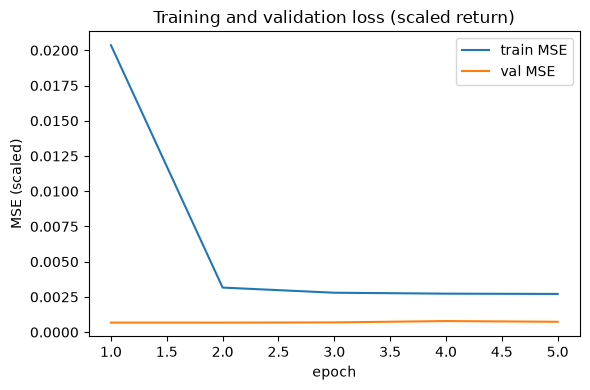

In [7]:
# To-Do (code): Adam + MSELoss, training and validation loops, print epoch losses
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

def run_one_epoch(loader, train=True):
    model.train() if train else model.eval()
    total_loss, total_n = 0.0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            pred = model(xb)
            loss = criterion(pred, yb)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * len(xb)
            total_n += len(xb)
    return total_loss / total_n

history = {'train': [], 'val': []}
best_val, best_state = float('inf'), None
for epoch in range(1, EPOCHS + 1):
    train_loss = run_one_epoch(train_loader, train=True)
    val_loss = run_one_epoch(val_loader, train=False)
    history['train'].append(train_loss)
    history['val'].append(val_loss)
    if val_loss < best_val:
        best_val = val_loss
        best_state = copy.deepcopy(model.state_dict())
    print(f'Epoch {epoch:2d}/{EPOCHS} | train MSE {train_loss:.5f} | val MSE {val_loss:.5f}')

model.load_state_dict(best_state)   # use the best epoch, not necessarily the last one
print('Restored best weights (lowest val MSE):', round(best_val, 5))

plt.figure(figsize=(6, 4))
plt.plot(range(1, EPOCHS + 1), history['train'], label='train MSE')
plt.plot(range(1, EPOCHS + 1), history['val'], label='val MSE')
plt.title('Training and validation loss (scaled return)')
plt.xlabel('epoch'); plt.ylabel('MSE (scaled)'); plt.legend(); plt.tight_layout(); plt.show()

# Part 7: Evaluate on the test set

**Task from the brief**
Turn the predicted return into a price with pred_price = today's Adj Close × (1 + pred_return). Plot actual vs predicted **prices**. Report R² and MAE on **price**, and also on **return**. Include the naive baseline (return = 0, so tomorrow's price = today's price) for both. Save the scaler with joblib and the model with `torch.save`.

**Learning point**
- **R²** measures how much of the variation the model explains. 1.0 is perfect. 0 means no better than always predicting the average.
- **Price R²** looks high for almost any model, because a price is a big number that changes only a little each day. **Return R²** is the harder test: it asks whether the model predicts the day-to-day move.
- That is why I report both, and why the naive baseline matters. For return = 0, the price R² is close to 1 by construction.

**What this cell does:** predicts the test windows, turns the scaled output back into a return with the target scaler's `inverse_transform`, then into a price with today's Adj Close. It computes R² and MAE on price and on return, for the LSTM and for the naive baseline, and prints them in one table.

In [8]:
# To-Do (code): test predictions, return -> price, metrics on price AND on return
def predict(loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            preds.append(model(xb.to(device)).cpu().numpy())
    return np.concatenate(preds)

pred_scaled = predict(test_loader)
pred_ret = target_scaler.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()   # back to a simple return
pred_price = test_today_adj * (1 + pred_ret)                                     # return -> price

# Naive baseline (my addition): return = 0, so tomorrow's price = today's price
zero_ret = np.zeros_like(pred_ret)
naive_price = test_today_adj * (1 + zero_ret)

def metrics(name, pred_p, pred_r):
    return {
        'model': name,
        'price R2': r2_score(test_next_adj, pred_p),
        'price MAE ($)': mean_absolute_error(test_next_adj, pred_p),
        'return R2': r2_score(test_actual_ret, pred_r),
        'return MAE (%)': mean_absolute_error(test_actual_ret, pred_r) * 100,
    }

results = pd.DataFrame([metrics('LSTM', pred_price, pred_ret),
                        metrics('Naive (return = 0)', naive_price, zero_ret)])
print('Test days:', len(test_rows))
display(results.round(4))

Test days: 1487


,model,price R2,price MAE ($),return R2,return MAE (%)
0,LSTM,0.9964,1.9235,-0.0695,1.2255
1,Naive (return = 0),0.9966,1.8269,-0.0028,1.1584


**What this cell does:** plots actual vs predicted prices (top) and actual vs predicted returns (bottom) for every day of the test period. Each point sits on the date of the day being predicted (tomorrow), so the lines line up with the calendar.

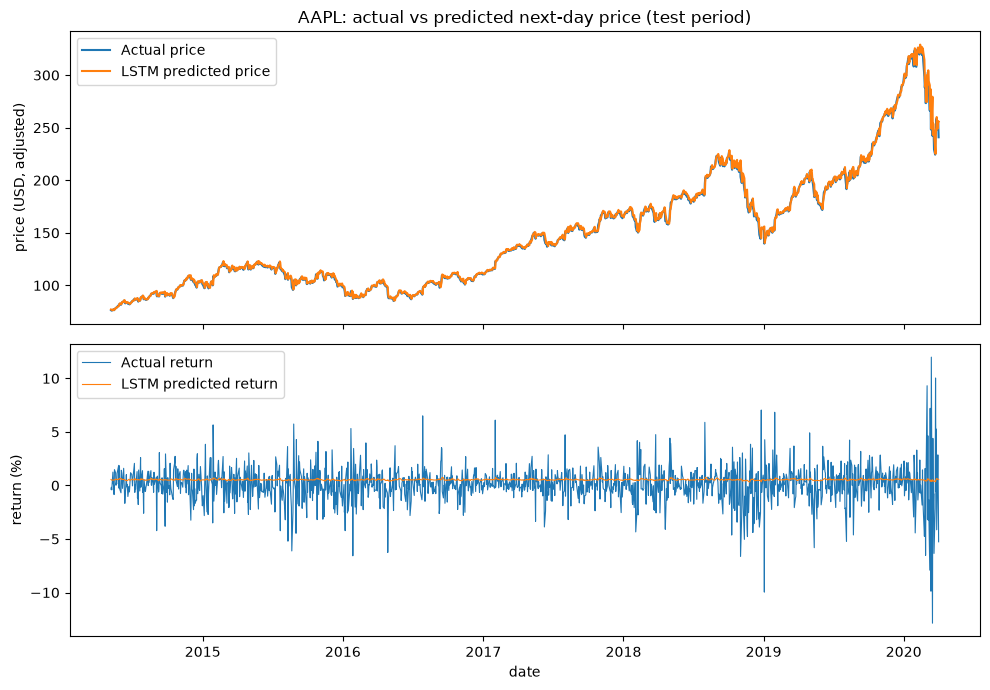

In [9]:
# Actual vs predicted on the test period: prices (top), returns (bottom)
d_next = stock.index[stock.index.get_indexer(d_test) + 1]   # the date of the day being predicted

fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
axes[0].plot(d_next, test_next_adj, label='Actual price')
axes[0].plot(d_next, pred_price, label='LSTM predicted price')
axes[0].set_title(f'{TICKER}: actual vs predicted next-day price (test period)')
axes[0].set_ylabel('price (USD, adjusted)'); axes[0].legend()
axes[1].plot(d_next, test_actual_ret * 100, label='Actual return', linewidth=0.8)
axes[1].plot(d_next, pred_ret * 100, label='LSTM predicted return', linewidth=0.8)
axes[1].set_ylabel('return (%)'); axes[1].set_xlabel('date'); axes[1].legend()
plt.tight_layout(); plt.show()

**Why these numbers (my reading of the result):**
- **Price looks great, but it does not tell much.** Both models get R² ≈ 0.996. The naive rule (tomorrow = today) is already a very good guess for a price, so this score mostly reflects that. The LSTM's price MAE is $1.92 against $1.83 for the naive rule, so it is slightly worse.
- **Returns are the honest test.** The naive rule (return = 0) has R² = −0.003, which is almost exactly zero, because the test-period average daily return is close to zero. The LSTM has R² = −0.070. Its predicted daily moves are worse than predicting no move at all, and its return MAE is 1.23% against 1.16%.
- **What the model is doing:** in the bottom plot, the LSTM's predicted return stays in a narrow band close to a flat line, just above zero. It is mostly predicting a small average drift, not the daily ups and downs. That is why it cannot beat a zero-return guess by much.
- **The range problem is fixed.** No test feature and no test target falls outside the 0 to 1 range learned from training. In the earlier price version, about 99.6% of test targets were above the training maximum. The inputs and target now stay in range, so the remaining gap is not a scaling problem. The model simply has little signal in past returns and volume.
- **Overfitting sign:** the validation MSE was lowest at epoch 2 (0.00067) and rose after that, while training MSE kept falling. The notebook keeps the epoch-2 weights, as the code says.
- **How much to trust this:** it is one run, with a small model, 5 epochs on CPU, and no tuning. Seed 42 is fixed, but I did not run other seeds or other date ranges, so small differences like $0.09 of MAE could change with a different setup. The clear result is that the LSTM does not beat a zero-return guess on this data.

**What this cell does:** saves the scalers with **joblib** to `scaler.pkl` (with the feature names, the lookback, and the target definition), and saves the model weights with **`torch.save`** to `lstm_stock.pt`. To use them later, load the scalers with `joblib.load` and the model with `model.load_state_dict(torch.load(...))`.

In [10]:
# Save the scalers (joblib) and the trained model weights (torch.save)
joblib.dump({'feature_scaler': feature_scaler, 'target_scaler': target_scaler,
             'feature_cols': feature_cols, 'lookback': LOOKBACK,
             'target': 'next-day simple return'}, 'scaler.pkl')
torch.save(model.state_dict(), 'lstm_stock.pt')
print('Saved scaler.pkl (joblib) and lstm_stock.pt (torch.save)')

Saved scaler.pkl (joblib) and lstm_stock.pt (torch.save)


**To-Do (written):** In plain words, what does R² mean? What does your number tell you?

**My answer:** R² tells me how much of the movement in the target the model explains, compared with always guessing the average. My **price R² is 0.9964**, but the naive rule "tomorrow = today" gets **0.9966**, so the price score does not show that the model learned anything. My **return R² is −0.0695**, below zero. That means the LSTM's predicted daily moves are worse than guessing a 0% move, which scores −0.0028 here. So in my run the LSTM did **not** beat the naive baseline on price or on return. I report that as it is. I did not tune the model to make it look better.

## Next steps (optional)
- Try a longer or shorter lookback (for example 30 or 120 days) and compare the return MAE.
- Check the result over other periods with a walk-forward test: retrain each year on the data before it, and see whether the LSTM still beats the zero-return baseline.
- Add more features, such as High and Low relative to Close, and check whether the validation loss improves.
- Run on a Colab GPU with `EPOCHS = 20` and compare the curves.